# Task 3 - Smart Inventory Management System

```
Sqrock IT Solutions - Data Science Internship - Phase 2

Real data: Montgomery County (Maryland, USA) Alcohol Beverage Services, a public
retailer/wholesaler that publishes its operations as open data.
  * store_inventory.csv   current stock on hand and shelf price of ~7,000 products
  * sales_history.csv.gz  monthly cases sold per product and supplier (28 months, 2017-2026):
                          retail (own stores) and wholesale (to licensed bars/shops)
  * purchases.csv         last month's purchase orders by vendor (stock entries)

Pipeline
  1. Load + clean (types, duplicates, missing suppliers, negative adjustments, validation)
  2. Product master: one row per product with stock, price, supplier, department
  3. Monthly demand history per product
  4. Demand forecasting: Naive / Moving Average / Linear Regression / Random Forest /
     XGBoost (GPU), tested on the two most recent months
  5. Stock status + alerts (out of stock, critical, low, overstock) from months of cover
  6. Insights: ABC classes, fast/slow movers, supplier and category performance
  7. Restocking recommendations

Stock on hand covers the whole operation (stores + warehouse), so demand is the total
leaving stock: retail sales + wholesale sales.

Two values are NOT published by the source and are derived, with the rule stated here:
  * units per case  - from the bottle/pack size (PACK_BY_SIZE below), to convert case sales to units
  * purchase cost   - shelf price x (1 - GROSS_MARGIN); ABS does not publish item costs

Run:  python task3_inventory/pipeline.py
```

In [1]:
import os, time
from IPython.display import Image, display
__file__ = os.path.abspath("pipeline.py")   # run from the task folder so the script's relative paths resolve
_seen = time.time()

def show_new_figures(folder=os.path.join("artifacts", "figures")):
    """Display the charts saved since the previous cell."""
    global _seen
    if os.path.isdir(folder):
        for f in sorted(os.listdir(folder), key=lambda f: os.path.getmtime(os.path.join(folder, f))):
            p = os.path.join(folder, f)
            if f.endswith(".png") and os.path.getmtime(p) >= _seen:
                display(Image(p))
    _seen = time.time()

In [2]:
from __future__ import annotations

import sys
from pathlib import Path
sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from limits import N_JOBS          # caps CPU threads and lowers process priority; must come before numpy

import json
import re
import time
import warnings
from pathlib import Path

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
SEED = 42
HERE = Path(__file__).resolve().parent
DATA = HERE.parent / "data" / "inventory"
ART = HERE / "artifacts"
(ART / "figures").mkdir(parents=True, exist_ok=True)

GROSS_MARGIN = 0.28          # assumed retail gross margin used to estimate purchase cost
TARGET_COVER = 1.5           # months of demand to hold after a restock
LOW_COVER, CRITICAL_COVER, OVERSTOCK_COVER = 1.0, 0.5, 6.0
PACK_BY_SIZE = {             # bottles in one case, by bottle size (multipacks are parsed from the name)
    "750ML": 12, "1.75L": 6, "1L": 12, "1.5L": 6, "375ML": 24, "200ML": 48, "100ML": 60,
    "50ML": 120, "700ML": 12, "500ML": 12, "187ML": 24, "3L": 4, "5L": 4, "4L": 4, "720ML": 12,
    "1LTR": 12, "5LTR": 4, "3LTR": 4, "355ML": 24, "250ML": 24, "300ML": 12, "12.0Z": 24,
}
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})


def log(msg: str) -> None:
    print(msg, flush=True)

## 1. Load + Clean

In [3]:
log("STEP 1 - Load and clean")
clean = {}
inv = pd.read_csv(DATA / "store_inventory.csv", dtype=str)
sales = pd.read_csv(DATA / "sales_history.csv.gz", dtype=str)
purch = pd.read_csv(DATA / "purchases.csv", dtype=str)
clean["rows_raw"] = {"inventory": len(inv), "sales": len(sales), "purchases": len(purch)}

# inventory snapshot
for c in ("code", "category", "description", "size"):
    inv[c] = inv[c].str.strip()
inv["stock_units"] = pd.to_numeric(inv["totalinventory"], errors="coerce")
inv["price"] = pd.to_numeric(inv["price"], errors="coerce")
inv["sale_price"] = pd.to_numeric(inv["saleprice"], errors="coerce")
inv["sale_end"] = pd.to_datetime(inv["saleenddate"], errors="coerce")
clean["inventory_duplicate_codes"] = int(inv["code"].duplicated().sum())
inv = inv.drop_duplicates(subset="code")
bad = inv["stock_units"].isna() | (inv["stock_units"] < 0) | inv["price"].isna() | (inv["price"] <= 0)
clean["inventory_invalid_rows_removed"] = int(bad.sum())
inv = inv[~bad].copy()
inv["name"] = inv["description"].str.replace(r"\s+", " ", regex=True)
inv["size"] = inv["size"].str.upper()

# sales history
for c in ("rtl_sales", "rtl_transfers", "whs_sales"):
    sales[c] = pd.to_numeric(sales[c], errors="coerce")
clean["sales_missing_supplier"] = int(sales["supplier"].isna().sum())
clean["sales_missing_values"] = int(sales[["rtl_sales", "rtl_transfers", "whs_sales"]].isna().sum().sum())
sales["supplier"] = sales["supplier"].fillna("UNKNOWN SUPPLIER").str.strip()
sales[["rtl_sales", "rtl_transfers", "whs_sales"]] = sales[["rtl_sales", "rtl_transfers", "whs_sales"]].fillna(0)
sales["item_type"] = sales["item_type"].fillna("UNKNOWN")
clean["sales_duplicates_removed"] = int(sales.duplicated().sum())
sales = sales.drop_duplicates()
# negative quantities are returns / stock corrections, not demand
clean["sales_negative_adjustments"] = int(((sales["rtl_sales"] < 0) | (sales["whs_sales"] < 0)).sum())
sales["demand_cases"] = sales["rtl_sales"].clip(lower=0) + sales["whs_sales"].clip(lower=0)
sales["retail_cases"] = sales["rtl_sales"].clip(lower=0)
sales["month"] = pd.to_datetime(sales["calendar_year"] + "-" + sales["cal_month_num"].str.zfill(2) + "-01")
# keep merchandise only (drop pallets/deposits/supplies bookkeeping rows)
keep = sales["item_type"].isin(["WINE", "LIQUOR", "BEER", "NON-ALCOHOL", "KEGS"])
clean["sales_non_merchandise_rows_removed"] = int((~keep).sum())
sales = sales[keep].copy()

# purchases (stock entries)
purch["quantity"] = pd.to_numeric(purch["quantity"], errors="coerce").fillna(0)
purch["entry_month"] = pd.to_datetime(purch["calendar_month"] + " " + purch["calendar_year"], format="%B %Y")
clean["rows_clean"] = {"inventory": len(inv), "sales": len(sales), "purchases": len(purch)}
for k, v in clean.items():
    log(f"  {k}: {v}")

MONTHS = sorted(sales["month"].unique())
LAST = MONTHS[-1]
log(f"  sales history: {len(MONTHS)} months, {pd.Timestamp(MONTHS[0]):%Y-%m} .. {pd.Timestamp(LAST):%Y-%m}")

STEP 1 - Load and clean


  rows_raw: {'inventory': 7020, 'sales': 352419, 'purchases': 8649}


  inventory_duplicate_codes: 0


  inventory_invalid_rows_removed: 0


  sales_missing_supplier: 217


  sales_missing_values: 7


  sales_duplicates_removed: 0


  sales_negative_adjustments: 885


  sales_non_merchandise_rows_removed: 737


  rows_clean: {'inventory': 7020, 'sales': 351682, 'purchases': 8649}


  sales history: 28 months, 2017-06 .. 2026-09


## 2. Product Master

In [4]:
log("STEP 2 - Product master")
demand = (sales.groupby(["item_code", "month"], as_index=False)
          .agg(cases=("demand_cases", "sum"), retail=("retail_cases", "sum"), transfers=("rtl_transfers", "sum")))
latest = sales.sort_values("month").groupby("item_code").tail(1).set_index("item_code")


def pack_size(size: str) -> int:
    """Containers in one sellable pack: 12 for a 12-pack, 1 for a single bottle."""
    m = re.fullmatch(r"(\d+)PK", str(size).upper().replace(" ", ""))
    return int(m.group(1)) if m else 1


def units_per_case(size: str, name: str) -> int:
    """Containers (bottles / cans) in one wholesale case. Stock is counted in containers."""
    n = pack_size(size)
    if n > 1:
        m = re.search(r"(\d+)\s*/\s*(\d+)", name)       # "2/12 NR" = 2 packs of 12 in a case
        if m and int(m.group(2)) == n and 1 <= int(m.group(1)) <= 12:
            return int(m.group(1)) * n
        return max(24, n) if n <= 24 else n            # the standard 24-container beer case
    return PACK_BY_SIZE.get(str(size).upper().replace(" ", ""), 12)   # 12 = standard wine/spirits case


prod = inv[["code", "name", "category", "size", "stock_units", "price", "sale_price", "sale_end"]].copy()
prod["units_per_case"] = [units_per_case(s, n) for s, n in zip(prod["size"], prod["name"])]
prod["pack_size"] = prod["size"].map(pack_size)          # the shelf price is per pack, stock is per container
prod["packs_in_stock"] = prod["stock_units"] / prod["pack_size"]
prod["supplier"] = prod["code"].map(latest["supplier"])
vendor = purch.sort_values("quantity").groupby("item")["vendor_name"].last()
prod["supplier"] = prod["supplier"].fillna(prod["code"].map(vendor)).fillna("UNKNOWN SUPPLIER")
prod["department"] = prod["code"].map(latest["item_type"])
dept_by_cat = prod.dropna(subset=["department"]).groupby("category")["department"].agg(lambda s: s.mode().iat[0])
prod["department"] = prod["department"].fillna(prod["category"].map(dept_by_cat)).fillna("OTHER")
# Beer sold as a whole loose case ("24 LOOSE", "30PK CAN", priced about $35) is counted in cases.
loose_case = (prod["department"] == "BEER") & (prod["pack_size"] == 1) & prod["size"].str.endswith("Z")
prod.loc[loose_case, "units_per_case"] = 1
prod["purchase_price"] = (prod["price"] * (1 - GROSS_MARGIN)).round(2)
prod["on_promotion"] = prod["sale_price"].notna()
po = purch.groupby("item").agg(last_entry=("entry_month", "max"), last_entry_cases=("quantity", "sum"))
prod["stock_entry_date"] = prod["code"].map(po["last_entry"])
prod["last_entry_cases"] = prod["code"].map(po["last_entry_cases"]).fillna(0)
prod["stock_value_retail"] = (prod["packs_in_stock"] * prod["price"]).round(2)
prod["stock_value_cost"] = (prod["packs_in_stock"] * prod["purchase_price"]).round(2)
log(f"  {len(prod):,} products | {prod['category'].nunique()} categories | {prod['supplier'].nunique()} suppliers")

STEP 2 - Product master


  7,020 products | 102 categories | 305 suppliers


## 3. Demand Panel + Features

In [5]:
log("STEP 3 - Demand history and features")
codes = prod["code"].tolist()
panel = (demand[demand["item_code"].isin(codes)]
         .pivot(index="item_code", columns="month", values="cases").reindex(index=codes, columns=MONTHS))
listed = panel.notna()                                   # was the product in the catalogue that month?
panel = panel.fillna(0.0)
month_no = {m: pd.Timestamp(m).year * 12 + pd.Timestamp(m).month for m in MONTHS}
dept_code = prod.set_index("code")["department"].astype("category").cat.codes
cat_code = prod.set_index("code")["category"].astype("category").cat.codes
log_price = np.log(prod.set_index("code")["price"])

FEATURES = ["lag_1", "lag_2", "lag_3", "age_1", "age_2", "age_3", "recent_mean", "recent_n", "trend", "mean_6", "std_6",
            "hist_mean", "months_listed", "same_month_prev", "same_month_age", "month_of_year", "dept", "category", "log_price"]
RECENT = 6                                              # months: older observations are treated as stale


def feature_frame(j: int) -> pd.DataFrame:
    """Features for predicting month index j from months < j (j may be len(MONTHS) = the future).

    The published history has gaps (up to six years), so every lag carries its age in
    months and the "recent" statistics only use observations from the last RECENT months.
    """
    past = panel.iloc[:, :j]
    target_no = month_no[MONTHS[j]] if j < len(MONTHS) else month_no[LAST] + 1
    ages = np.array([target_no - month_no[m] for m in MONTHS[:j]])
    f = pd.DataFrame(index=panel.index)
    for k in (1, 2, 3):
        f[f"lag_{k}"] = past.iloc[:, -k]
        f[f"age_{k}"] = ages[-k]
    recent = past.loc[:, ages <= RECENT]
    f["recent_mean"] = recent.mean(axis=1)
    f["recent_n"] = recent.shape[1]
    f["trend"] = (recent.iloc[:, -1] - recent.iloc[:, 0]) if recent.shape[1] >= 2 else 0.0
    f["mean_6"] = past.iloc[:, -6:].mean(axis=1)
    f["std_6"] = past.iloc[:, -6:].std(axis=1)
    f["hist_mean"] = past.mean(axis=1)
    f["months_listed"] = listed.iloc[:, :j].sum(axis=1)
    moy = (target_no - 1) % 12 + 1
    same = [m for m in MONTHS[:j] if pd.Timestamp(m).month == moy]
    f["same_month_prev"] = past[same[-1]] if same else f["mean_6"]
    f["same_month_age"] = target_no - month_no[same[-1]] if same else 0
    f["month_of_year"] = moy
    f["dept"], f["category"], f["log_price"] = dept_code, cat_code, log_price
    f["recent_mean"] = f["recent_mean"].fillna(f["lag_1"])     # nothing recent on record: fall back to the last value
    return f.fillna(0.0)


rows = []
for j in range(6, len(MONTHS)):
    f = feature_frame(j)
    f["y"], f["month"] = panel.iloc[:, j], MONTHS[j]
    rows.append(f[(f["months_listed"] > 0) | (f["y"] > 0)])       # only products that exist by then
train_all = pd.concat(rows).reset_index(names="code")
TEST_MONTHS = MONTHS[-2:]
tr = train_all[~train_all["month"].isin(TEST_MONTHS)]
te = train_all[train_all["month"].isin(TEST_MONTHS)]
log(f"  training rows {len(tr):,} ({tr['month'].nunique()} months) | test rows {len(te):,} "
    f"({', '.join(pd.Timestamp(m).strftime('%Y-%m') for m in TEST_MONTHS)})")

STEP 3 - Demand history and features


  training rows 73,329 (20 months) | test rows 13,095 (2026-08, 2026-09)


## 4. Forecast Models

In [6]:
log("STEP 4 - Demand forecasting models")
Xtr, Xte = tr[FEATURES], te[FEATURES]
# Demand is heavily skewed, so models learn on a log scale. They predict the CHANGE from last
# month's demand rather than the level: a model that learns nothing then equals the naive forecast.
base_tr, base_te = np.log1p(Xtr["lag_1"]), np.log1p(Xte["lag_1"])
ytr_log = np.log1p(tr["y"]) - base_tr


def fit_xgb(device: str):
    # absolute-error objective: robust to the few huge products, and it is what WAPE measures
    m = xgb.XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=5, min_child_weight=30,
                         subsample=0.8, colsample_bytree=0.8, objective="reg:absoluteerror",
                         tree_method="hist", n_jobs=N_JOBS, device=device,
                         random_state=SEED, verbosity=0)
    return m.fit(Xtr, ytr_log)


t0 = time.time()
try:
    import torch
    xgb_device = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    xgb_device = "cpu"
try:
    xgb_model = fit_xgb(xgb_device)
except Exception:
    xgb_device = "cpu"
    xgb_model = fit_xgb("cpu")
xgb_model.set_params(device="cpu")
log(f"  XGBoost trained on {xgb_device} in {time.time() - t0:.1f}s")

lin_cols = [c for c in FEATURES if c not in ("dept", "category", "trend")]
lin = LinearRegression().fit(np.log1p(Xtr[lin_cols].clip(lower=0)), ytr_log)
rf = RandomForestRegressor(n_estimators=200, max_depth=14, min_samples_leaf=5, max_features=0.6,
                           n_jobs=N_JOBS, random_state=SEED).fit(Xtr, ytr_log)

back = lambda X, change: np.clip(np.expm1(np.log1p(X["lag_1"].values) + change), 0, None)
predict = {
    "Naive (last month)": lambda X: X["lag_1"].values,
    "Moving Average (recent months)": lambda X: X["recent_mean"].values,
    "Linear Regression": lambda X: back(X, lin.predict(np.log1p(X[lin_cols].clip(lower=0)))),
    "Random Forest": lambda X: back(X, rf.predict(X)),
    "XGBoost": lambda X: back(X, xgb_model.predict(X)),
}
evaluation = {}
for name, fn in predict.items():
    p = fn(Xte)
    evaluation[name] = {
        "MAE_cases": round(float(mean_absolute_error(te["y"], p)), 3),
        "RMSE_cases": round(float(np.sqrt(mean_squared_error(te["y"], p))), 3),
        "WAPE_pct": round(float(np.abs(te["y"] - p).sum() / te["y"].sum() * 100), 2),
        "Bias_pct": round(float((p.sum() / te["y"].sum() - 1) * 100), 2),
    }
    log(f"  {name:26s} MAE {evaluation[name]['MAE_cases']:6.3f}  RMSE {evaluation[name]['RMSE_cases']:7.3f}  "
        f"WAPE {evaluation[name]['WAPE_pct']:5.1f}%  bias {evaluation[name]['Bias_pct']:+.1f}%")
best = min(evaluation, key=lambda k: evaluation[k]["WAPE_pct"])
log(f"  --> best model by WAPE: {best}")

# forecast the month after the last one on record, for every product
future = feature_frame(len(MONTHS))
next_month = pd.Timestamp(LAST) + pd.DateOffset(months=1)
prod = prod.set_index("code")
prod["forecast_cases"] = np.round(predict[best](future[FEATURES]), 2)
prod["avg_cases_3m"] = panel.iloc[:, -3:].mean(axis=1).round(2)
prod["sold_cases_12m"] = panel.iloc[:, -4:].sum(axis=1).round(2)       # the 4 months on record for 2026
prod["last_sale_month"] = panel.apply(lambda r: r[r > 0].index.max() if (r > 0).any() else pd.NaT, axis=1)
prod["forecast_units"] = (prod["forecast_cases"] * prod["units_per_case"]).round(0)

STEP 4 - Demand forecasting models


  XGBoost trained on cuda in 5.5s


  Naive (last month)         MAE  8.044  RMSE  53.765  WAPE  22.2%  bias +3.0%


  Moving Average (recent months) MAE  7.620  RMSE  52.361  WAPE  21.0%  bias +10.3%


  Linear Regression          MAE 10.694  RMSE  75.870  WAPE  29.5%  bias +5.5%


  Random Forest              MAE  7.681  RMSE  66.484  WAPE  21.2%  bias +3.0%


  XGBoost                    MAE  8.223  RMSE  63.517  WAPE  22.7%  bias +6.4%


  --> best model by WAPE: Moving Average (recent months)


## 5. Stock Status + Alerts

In [7]:
log("STEP 5 - Stock status and alerts")
recent_sales = panel.iloc[:, -4:].sum(axis=1) > 0
MIN_DEMAND = 1.0                                         # cases a month; below this a product is special-order
selling_now = (panel.iloc[:, -1] > 0) & (prod["forecast_cases"] >= MIN_DEMAND)
prod["active"] = recent_sales | (prod["stock_units"] > 0)
prod["months_cover"] = np.where(prod["forecast_units"] > 0, prod["stock_units"] / prod["forecast_units"], np.inf)


def status(r) -> str:
    if r["stock_units"] == 0:
        return "Out of Stock" if selling_now[r.name] else "Inactive"
    if r["forecast_units"] <= 0:
        return "Overstock" if not recent_sales[r.name] else "Healthy"
    if r["months_cover"] < CRITICAL_COVER:
        return "Critical"
    if r["months_cover"] < LOW_COVER:
        return "Low Stock"
    if r["months_cover"] > OVERSTOCK_COVER:
        return "Overstock"
    return "Healthy"


prod["stock_status"] = prod.apply(status, axis=1)
need = (TARGET_COVER * prod["forecast_units"] - prod["stock_units"]).clip(lower=0)
prod["reorder_cases"] = np.where(prod["stock_status"].isin(["Out of Stock", "Critical", "Low Stock"]),
                                 np.ceil(need / prod["units_per_case"]), 0).astype(int)
packs_per_case = prod["units_per_case"] / prod["pack_size"]
prod["reorder_cost"] = (prod["reorder_cases"] * packs_per_case * prod["purchase_price"]).round(2)
prod["lost_sales_risk"] = np.where(prod["stock_status"].eq("Out of Stock"),
                                   prod["forecast_cases"] * packs_per_case * prod["price"], 0).round(2)
log("  " + prod["stock_status"].value_counts().to_string().replace("\n", "\n  "))

STEP 5 - Stock status and alerts


  stock_status
  Inactive        2291
  Out of Stock    1962
  Healthy         1757
  Low Stock        475
  Critical         278
  Overstock        257


## 6. Insights

In [8]:
log("STEP 6 - Insights (ABC, movers, suppliers, categories)")
prod["revenue_recent"] = (panel.iloc[:, -4:].sum(axis=1) * packs_per_case * prod["price"]).round(2)
rank = prod["revenue_recent"].sort_values(ascending=False)
share = rank.cumsum() / rank.sum()
prod["abc_class"] = pd.cut(share.reindex(prod.index), [0, 0.8, 0.95, 1.0001], labels=["A", "B", "C"]).astype(str)
prod.loc[prod["revenue_recent"] <= 0, "abc_class"] = "C"
sold = prod[prod["avg_cases_3m"] > 0]["avg_cases_3m"]
fast_cut, slow_cut = sold.quantile(0.90), sold.quantile(0.25)
prod["movement"] = np.select(
    [prod["avg_cases_3m"] >= fast_cut, (prod["avg_cases_3m"] > 0) & (prod["avg_cases_3m"] <= slow_cut),
     prod["avg_cases_3m"] <= 0], ["Fast-moving", "Slow-moving", "No recent sales"], "Regular")

act = prod[prod["active"]]
supplier = act.groupby("supplier").agg(
    products=("name", "count"), stock_units=("stock_units", "sum"), stock_value=("stock_value_retail", "sum"),
    revenue_recent=("revenue_recent", "sum"), forecast_cases=("forecast_cases", "sum"),
    out_of_stock=("stock_status", lambda s: int((s == "Out of Stock").sum())),
    low_or_critical=("stock_status", lambda s: int(s.isin(["Low Stock", "Critical"]).sum())),
).reset_index()
supplier["stockout_rate_pct"] = (supplier["out_of_stock"] / supplier["products"] * 100).round(1)
r4 = sales[sales["month"].isin(MONTHS[-4:])].groupby("supplier").agg(sold=("retail_cases", "sum"),
                                                                      delivered=("rtl_transfers", "sum"))
supplier["delivered_vs_sold_pct"] = supplier["supplier"].map((r4["delivered"] / r4["sold"].replace(0, np.nan) * 100).round(1))
supplier = supplier.sort_values("revenue_recent", ascending=False)

category = act.groupby(["department", "category"]).agg(
    products=("name", "count"), stock_units=("stock_units", "sum"), stock_value=("stock_value_retail", "sum"),
    revenue_recent=("revenue_recent", "sum"), forecast_cases=("forecast_cases", "sum"),
    out_of_stock=("stock_status", lambda s: int((s == "Out of Stock").sum())),
    overstock=("stock_status", lambda s: int((s == "Overstock").sum())),
).reset_index().sort_values("revenue_recent", ascending=False)

dept_of = prod["department"]
trend = (demand[demand["item_code"].isin(codes)].assign(department=lambda d: d["item_code"].map(dept_of))
         .groupby(["month", "department"], as_index=False)
         .agg(cases_sold=("cases", "sum"), cases_delivered=("transfers", "sum")))

STEP 6 - Insights (ABC, movers, suppliers, categories)


## 7. Save

STEP 7 - Saving artifacts



  KPI


    total_products               7,020


    active_products              6,461


    total_categories             102


    total_suppliers              305


... (11 outputs left out)

    reorder_cost_est             9,562,744.27


    lost_sales_risk_month        2,545,898.87


    overstock_value_retail       5,049,666.06


TASK 3 COMPLETE


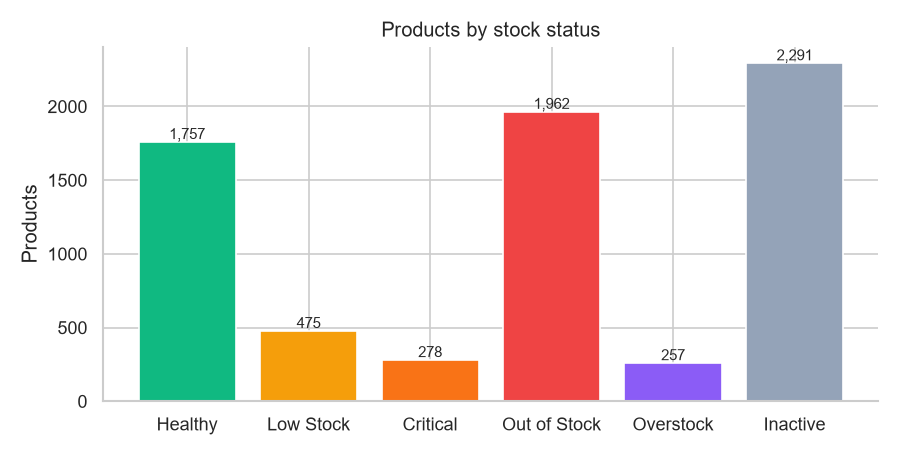

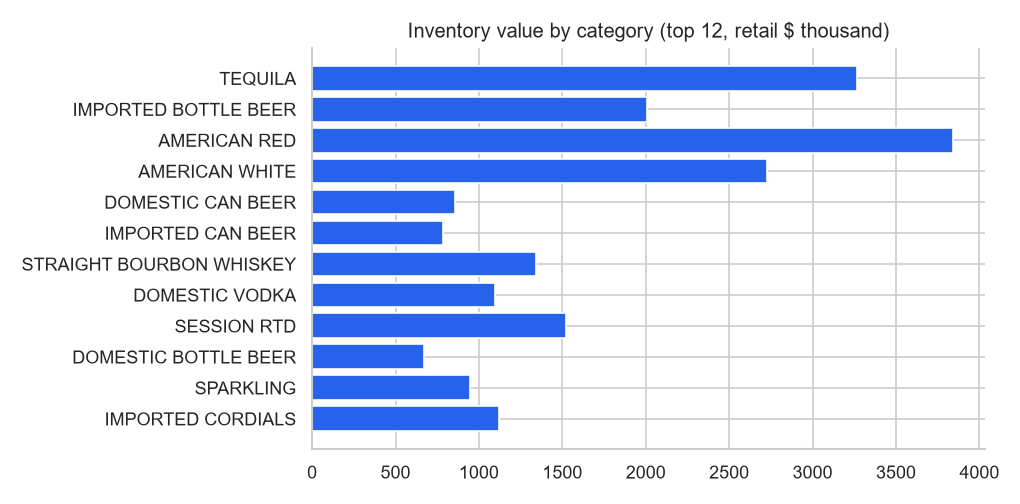

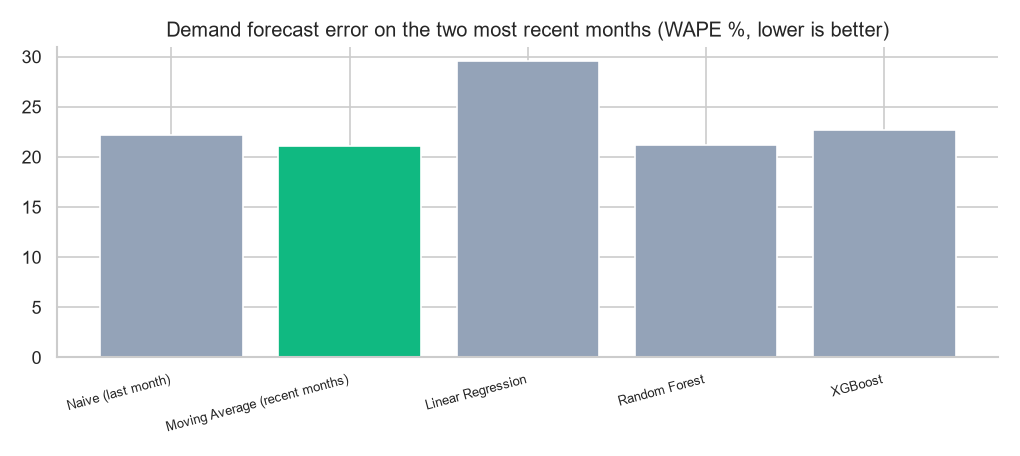

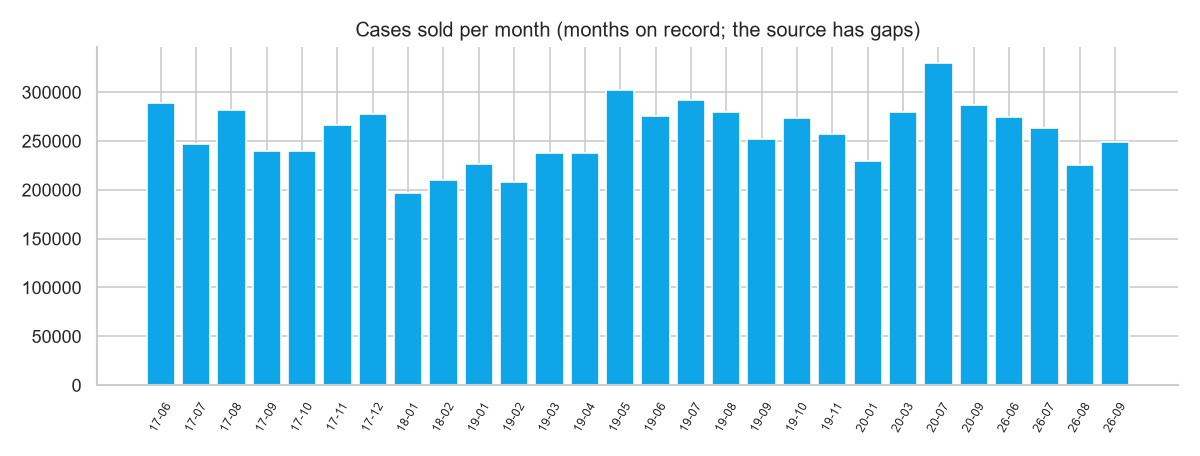

In [9]:
log("STEP 7 - Saving artifacts")
prod = prod.reset_index()
cols = ["code", "name", "department", "category", "size", "supplier", "stock_units", "units_per_case", "pack_size", "purchase_price",
        "price", "sale_price", "on_promotion", "stock_entry_date", "last_entry_cases", "stock_status", "months_cover",
        "forecast_cases", "forecast_units", "avg_cases_3m", "last_sale_month", "reorder_cases", "reorder_cost",
        "lost_sales_risk", "stock_value_retail", "stock_value_cost", "revenue_recent", "abc_class", "movement", "active"]
out = prod[cols].copy()
out["months_cover"] = out["months_cover"].replace(np.inf, np.nan).round(2)
out.to_csv(ART / "products.csv", index=False)
supplier.round(2).to_csv(ART / "supplier_performance.csv", index=False)
category.round(2).to_csv(ART / "category_performance.csv", index=False)
trend.round(2).to_csv(ART / "monthly_trend.csv", index=False)
hist = panel.round(2)
hist.columns = [pd.Timestamp(m).strftime("%Y-%m") for m in MONTHS]
hist.reset_index(names="code").to_csv(ART / "demand_history.csv.gz", index=False)
alerts = out[out["stock_status"].isin(["Out of Stock", "Critical", "Low Stock"])].sort_values(
    ["lost_sales_risk", "forecast_cases"], ascending=False)
alerts.to_csv(ART / "alerts.csv", index=False)
joblib.dump({"model": xgb_model, "features": FEATURES}, ART / "demand_model.joblib", compress=3)

active = out[out["active"]]
kpi = {
    "total_products": int(len(out)), "active_products": int(len(active)),
    "total_categories": int(out["category"].nunique()), "total_suppliers": int(out["supplier"].nunique()),
    "available_stock_units": int(out["stock_units"].sum()),
    "inventory_value_retail": round(float(out["stock_value_retail"].sum()), 2),
    "inventory_value_cost_est": round(float(out["stock_value_cost"].sum()), 2),
    "out_of_stock": int((out["stock_status"] == "Out of Stock").sum()),
    "critical": int((out["stock_status"] == "Critical").sum()),
    "low_stock": int((out["stock_status"] == "Low Stock").sum()),
    "overstock": int((out["stock_status"] == "Overstock").sum()),
    "healthy": int((out["stock_status"] == "Healthy").sum()),
    "inactive": int((out["stock_status"] == "Inactive").sum()),
    "reorder_lines": int((out["reorder_cases"] > 0).sum()),
    "reorder_cases": int(out["reorder_cases"].sum()),
    "reorder_cost_est": round(float(out["reorder_cost"].sum()), 2),
    "lost_sales_risk_month": round(float(out["lost_sales_risk"].sum()), 2),
    "overstock_value_retail": round(float(out.loc[out["stock_status"] == "Overstock", "stock_value_retail"].sum()), 2),
}
metrics = {
    "task": "Smart Inventory Management System",
    "dataset": "Montgomery County (MD) Alcohol Beverage Services open data",
    "history_months": [pd.Timestamp(m).strftime("%Y-%m") for m in MONTHS],
    "forecast_month": next_month.strftime("%Y-%m"),
    "cleaning": clean, "kpi": kpi,
    "forecast": {"features": FEATURES, "test_months": [pd.Timestamp(m).strftime("%Y-%m") for m in TEST_MONTHS],
                 "train_rows": int(len(tr)), "test_rows": int(len(te)), "models": evaluation, "best_model": best,
                 "xgboost_device": xgb_device,
                 "feature_importance": dict(sorted(zip(FEATURES, map(float, xgb_model.feature_importances_.round(4))),
                                                   key=lambda kv: -kv[1]))},
    "assumptions": {"gross_margin_for_cost_estimate": GROSS_MARGIN, "target_cover_months": TARGET_COVER,
                    "low_cover_months": LOW_COVER, "critical_cover_months": CRITICAL_COVER,
                    "overstock_cover_months": OVERSTOCK_COVER, "units_per_case_by_size": PACK_BY_SIZE},
    "abc": {k: {"products": int((active["abc_class"] == k).sum()),
                "revenue_share_pct": round(float(active.loc[active["abc_class"] == k, "revenue_recent"].sum()
                                                 / max(active["revenue_recent"].sum(), 1) * 100), 1)} for k in "ABC"},
}
(ART / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str))

# report figures
fig, ax = plt.subplots(figsize=(7.5, 3.8))
order = ["Healthy", "Low Stock", "Critical", "Out of Stock", "Overstock", "Inactive"]
pal = ["#10b981", "#f59e0b", "#f97316", "#ef4444", "#8b5cf6", "#94a3b8"]
vc = out["stock_status"].value_counts().reindex(order).fillna(0)
ax.bar(vc.index, vc.values, color=pal)
for i, v in enumerate(vc.values):
    ax.text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=9)
ax.set_title("Products by stock status"); ax.set_ylabel("Products")
fig.tight_layout(); fig.savefig(ART / "figures" / "stock_status.png"); plt.close(fig)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
top = category.head(12).iloc[::-1]
ax.barh(top["category"], top["stock_value"] / 1e3, color="#2563eb")
ax.set_title("Inventory value by category (top 12, retail $ thousand)")
fig.tight_layout(); fig.savefig(ART / "figures" / "category_value.png"); plt.close(fig)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ev = pd.DataFrame(evaluation).T
ax.bar(ev.index, ev["WAPE_pct"], color=["#10b981" if n == best else "#94a3b8" for n in ev.index])
ax.set_title("Demand forecast error on the two most recent months (WAPE %, lower is better)")
ax.set_xticklabels(ev.index, rotation=15, ha="right", fontsize=8)
fig.tight_layout(); fig.savefig(ART / "figures" / "forecast_models.png"); plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 3.8))
tt = trend.groupby("month")["cases_sold"].sum()
ax.bar([pd.Timestamp(m).strftime("%y-%m") for m in tt.index], tt.values, color="#0ea5e9")
ax.set_title("Cases sold per month (months on record; the source has gaps)")
ax.set_xticklabels([pd.Timestamp(m).strftime("%y-%m") for m in tt.index], rotation=60, fontsize=7)
fig.tight_layout(); fig.savefig(ART / "figures" / "monthly_trend.png"); plt.close(fig)

log("\n  KPI")
for k, v in kpi.items():
    log(f"    {k:28s} {v:,}")
log("TASK 3 COMPLETE")
show_new_figures()